<a href="https://colab.research.google.com/github/aashish7542/ai-learning/blob/main/phase-0-foundations/python/phase%200.3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This is about Pandas and working with data, which will be cruical in making our final project of Phase 0.

In [5]:
import pandas as pd

df = pd.DataFrame({
    "size": [1000, 1500, 2000, 1800],
    "bedrooms": [2, 3, 4, None],
    "price": [200000, 280000, 350000, 310000]
})

red_line("Info")
df.info()
red_line("Head")
print(df.head)
red_line("shape")
print(df.shape)
red_line("describe")
df.describe()


   INFO

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   size      4 non-null      int64  
 1   bedrooms  3 non-null      float64
 2   price     4 non-null      int64  
dtypes: float64(1), int64(2)
memory usage: 228.0 bytes

   HEAD

<bound method NDFrame.head of    size  bedrooms   price
0  1000       2.0  200000
1  1500       3.0  280000
2  2000       4.0  350000
3  1800       NaN  310000>

   SHAPE

(4, 3)

   DESCRIBE



,size,bedrooms,price
count,4.000000,3.0,4.000000
mean,1575.000000,3.0,285000.000000
std,434.932945,1.0,63508.529611
min,1000.000000,2.0,200000.000000
25%,1375.000000,2.5,260000.000000
50%,1650.000000,3.0,295000.000000
75%,1850.000000,3.5,320000.000000
max,2000.000000,4.0,350000.000000


I have introduced a function below that will be used to separate the clusters of output, making it look better

In [3]:
def red_line(title=""):
    # Prints a thick red line with an optional title
    color_red = "\033[91m"
    color_reset = "\033[0m"
    line = "=" * 60
    if title:
        print(f"\n{color_red}{line}\n   {title.upper()}\n{line}{color_reset}\n")
    else:
        print(f"\n{color_red}{line}{color_reset}\n")

**Real world Datasets**
Now we are importing a datasets about exoplanets from a github repo: https://github.com/mwaskom/seaborn-data/blob/master/planets.csv

In [5]:
import pandas as pd

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/planets.csv"

df = pd.read_csv(url)

print(df.shape)
display(df.head())

print(df.isna().sum())

(1035, 6)


,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300,7.10,77.40,2006
1,Radial Velocity,1,874.774,2.21,56.95,2008
2,Radial Velocity,1,763.000,2.60,19.84,2011
3,Radial Velocity,1,326.030,19.40,110.62,2007
4,Radial Velocity,1,516.220,10.50,119.47,2009


method              0
number              0
orbital_period     43
mass              522
distance          227
year                0
dtype: int64


**Cleaning Data**
The cells below are about identifying unsual values and cleaning them, if necessary.

In [3]:
pd.crosstab(df["method"], df["mass"].isna())

mass,False,True
method,,
Astrometry,0,2
Eclipse Timing Variations,2,7
Imaging,0,38
Microlensing,0,23
Orbital Brightness Modulation,0,3
Pulsar Timing,0,5
Pulsation Timing Variations,0,1
Radial Velocity,510,43
Transit,1,396


In [6]:
clean = df.dropna(subset=["orbital_period", "distance"])

print(df.shape)
print(clean.shape)

(1035, 6)
(776, 6)


In [7]:
df.duplicated().sum()

np.int64(4)

In [17]:
df[df.duplicated(keep=False)]


,method,number,orbital_period,mass,distance,year
33,Imaging,1,NaN,NaN,NaN,2008
902,Microlensing,1,NaN,NaN,NaN,2008
903,Microlensing,1,NaN,NaN,NaN,2008
904,Microlensing,1,NaN,NaN,NaN,2009
923,Microlensing,1,NaN,NaN,NaN,2009
925,Microlensing,2,NaN,NaN,4080.0,2012
926,Microlensing,2,NaN,NaN,4080.0,2012
957,Imaging,1,NaN,NaN,NaN,2008


In [18]:
df[["orbital_period", "mass", "distance"]].describe()

,orbital_period,mass,distance
count,992.000000,513.000000,808.000000
mean,2002.917596,2.638161,264.069282
std,26014.728304,3.818617,733.116493
min,0.090706,0.003600,1.350000
25%,5.442540,0.229000,32.560000
50%,39.979500,1.260000,55.250000
75%,526.005000,3.040000,178.500000
max,730000.000000,25.000000,8500.000000


In [19]:
(df["orbital_period"] <= 0).sum()

np.int64(0)

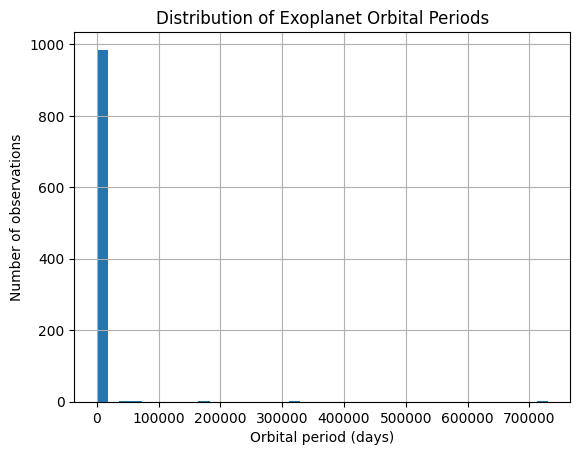

In [20]:
import matplotlib.pyplot as plt

df["orbital_period"].dropna().hist(bins=40)

plt.xlabel("Orbital period (days)")
plt.ylabel("Number of observations")
plt.title("Distribution of Exoplanet Orbital Periods")
plt.show()

**Since the histogram shows unusually large values in very small numbers, we will use a logathrimic function to analyse them.**

In [21]:
df.head()

,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300,7.10,77.40,2006
1,Radial Velocity,1,874.774,2.21,56.95,2008
2,Radial Velocity,1,763.000,2.60,19.84,2011
3,Radial Velocity,1,326.030,19.40,110.62,2007
4,Radial Velocity,1,516.220,10.50,119.47,2009
